# Raah: synthetic traffic EDA

Seed **57**. Educational synthetic aggregates, **not live GPS**. All syllabus topics remain **UNVERIFIED**.

> **FEATURE-DERIVED LABEL WARNING:** `congestion_level` is computed directly from speed/reference-speed ratio, vehicle count, queue length and current waiting time. High classification accuracy with those inputs can simply reproduce the label rule and **inflate apparent accuracy** if presented as independent congestion discovery. A grouped split does not eliminate this circular target definition. `future_wait_seconds` is a separate, exact 60-second future outcome; neither target is an input feature.

Full-data inspection below is limited to structural audits (shape, dtypes, nulls, duplicates and provenance). Feature/target charts use a fixed **training-only** run split. Validation/test run values are not used to select transformations, thresholds or models. No model is fitted and no imputation or outlier removal is performed.


In [1]:
from pathlib import Path
import hashlib
import json
import os
import platform

for candidate in [Path.cwd(), *Path.cwd().parents]:
    if (candidate / 'ml-service/data/traffic_observations.csv').is_file() and (candidate / 'AGENTS.md').is_file():
        ROOT = candidate
        break
else:
    raise FileNotFoundError('Run this notebook from inside the Raah repository')

ARTIFACTS = ROOT / 'artifacts/eda'
ARTIFACTS.mkdir(parents=True, exist_ok=True)
os.environ.setdefault('MPLCONFIGDIR', str(ROOT / 'work/matplotlib'))
os.environ.setdefault('MPLBACKEND', 'Agg')
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

SEED = 57
DATA = ROOT / 'ml-service/data'
INPUTS = sorted(DATA.glob('*.csv'))
input_hashes = {p.name: hashlib.sha256(p.read_bytes()).hexdigest() for p in INPUTS}
sns.set_theme(style='whitegrid', context='notebook', palette='colorblind')
plt.rcParams.update({'figure.dpi': 110, 'savefig.dpi': 150, 'axes.titleweight': 'bold'})
chart_paths = []

def save_chart(fig, filename):
    path = ARTIFACTS / filename
    fig.savefig(path, bbox_inches='tight', facecolor='white')
    chart_paths.append(path)
    if '_raah_emit_png' in globals():
        _raah_emit_png(path)
    else:
        try:
            from IPython.display import Image, display
            display(Image(filename=str(path)))
        except ImportError:
            print('Chart saved:', path)
    plt.close(fig)

df = pd.read_csv(DATA / 'traffic_observations.csv')
metadata = pd.read_csv(DATA / 'run_metadata.csv')
assert metadata.run_id.is_unique
assert metadata.source_kind.eq('synthetic').all() and metadata.seed.eq(57).all()
assert set(df.run_id) == set(metadata.run_id)
assert len(df.columns) == 17  # 15 observation fields + 2 targets, not 17 predictors.
print('Python:', platform.python_version(), 'pandas:', pd.__version__, 'numpy:', np.__version__)
print('Matplotlib:', matplotlib.__version__, 'seaborn:', sns.__version__)
print('Labeled shape:', df.shape, '| metadata shape:', metadata.shape)
print('Runs:', df.run_id.nunique(), '| virtual junctions:', df.intersection_id.nunique())
print('Dtypes:\n' + df.dtypes.astype(str).to_string())
print('No raw data is changed; charts use training groups only.')


Python: 3.12.14 pandas: 3.1.0 numpy: 2.5.4
Matplotlib: 3.11.2 seaborn: 0.13.2
Labeled shape: (14520, 17) | metadata shape: (30, 24)
Runs: 30 | virtual junctions: 1
Dtypes:
run_id                       str
timestamp_seconds          int64
intersection_id              str
approach_id                  str
mean_speed_kmh           float64
free_flow_speed_kmh      float64
vehicle_count              int64
queue_length_vehicles      int64
mean_wait_seconds        float64
incoming_vehicles          int64
outgoing_vehicles          int64
current_phase                str
seconds_in_phase         float64
time_of_day              float64
gps_sample_count           int64
congestion_level             str
future_wait_seconds      float64
No raw data is changed; charts use training groups only.


## Structural audit: nulls, duplicates and ordering

A blank speed is intentional missing coverage, not zero traffic or stopped speed. Count fields are simulator truth; they are not GPS packet counts. Duplicate rows and duplicate observation keys are checked separately.


                       null_count  null_percent
run_id                          0          0.00
timestamp_seconds               0          0.00
intersection_id                 0          0.00
approach_id                     0          0.00
mean_speed_kmh               2761         19.02
free_flow_speed_kmh             0          0.00
vehicle_count                   0          0.00
queue_length_vehicles           0          0.00
mean_wait_seconds               0          0.00
incoming_vehicles               0          0.00
outgoing_vehicles               0          0.00
current_phase                   0          0.00
seconds_in_phase                0          0.00
time_of_day                     0          0.00
gps_sample_count                0          0.00
congestion_level                0          0.00
future_wait_seconds             0          0.00
Exact duplicate rows: 0 | duplicate keys: 0
Time ordering: monotone within every run/approach. Speed missing iff no samples: PASS.


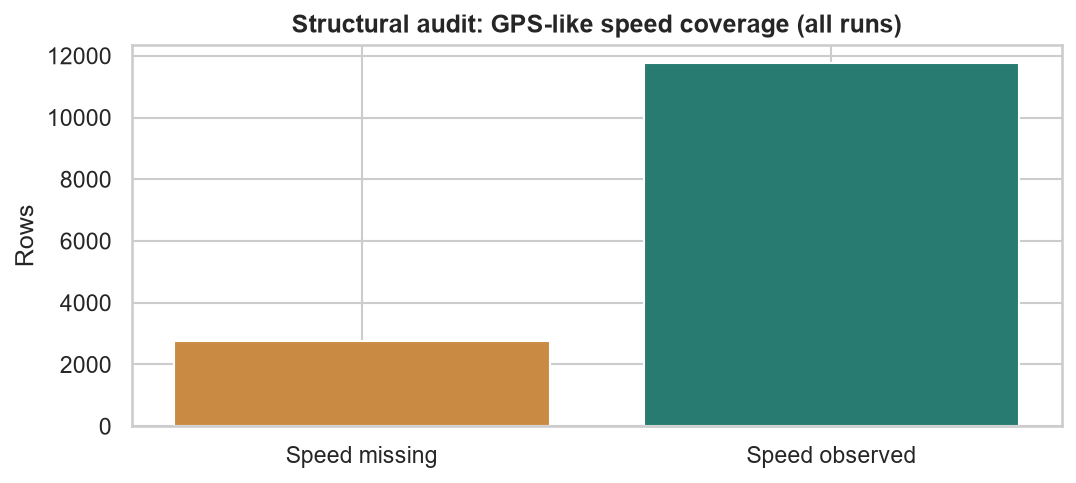

Takeaway: 2,761 of 14,520 rows (19.02%) have no synthetic speed sample. These are intentional nulls, not zero speeds. No other column has missing values; no rows are dropped or imputed.


In [2]:
null_counts = df.isna().sum()
null_table = pd.DataFrame({'null_count': null_counts, 'null_percent': 100 * null_counts / len(df)})
key = ['run_id', 'timestamp_seconds', 'intersection_id', 'approach_id']
duplicate_rows = int(df.duplicated().sum())
duplicate_keys = int(df.duplicated(key).sum())
missing_speed = df.mean_speed_kmh.isna()
assert (missing_speed == df.gps_sample_count.eq(0)).all()
assert null_counts.drop('mean_speed_kmh').eq(0).all()
assert duplicate_rows == duplicate_keys == 0
assert df.groupby(['run_id', 'approach_id']).timestamp_seconds.apply(lambda x: x.is_monotonic_increasing).all()
print(null_table.round(2).to_string())
print('Exact duplicate rows:', duplicate_rows, '| duplicate keys:', duplicate_keys)
print('Time ordering: monotone within every run/approach. Speed missing iff no samples: PASS.')

fig, ax = plt.subplots(figsize=(8, 3.3))
ax.bar(['Speed missing', 'Speed observed'], [int(missing_speed.sum()), int((~missing_speed).sum())], color=['#c98b44','#277b70'])
ax.set(title='Structural audit: GPS-like speed coverage (all runs)', ylabel='Rows')
save_chart(fig, '01_speed_coverage.png')
print(f'Takeaway: {missing_speed.sum():,} of {len(df):,} rows ({100*missing_speed.mean():.2f}%) have no synthetic speed sample. These are intentional nulls, not zero speeds. No other column has missing values; no rows are dropped or imputed.')


## Reproducible run-separated analysis split

Each demand archetype has six independently seeded runs. Within each archetype, seed 57 shuffles sorted run IDs into four training, one validation and one test run. All approaches and correlated windows from a run stay together. This is a run-generalization split, not a held-out-archetype experiment. The mapping is saved for later experiments; nothing is trained here.


split                 test  train  validation
scenario_type                                
asymmetric_rush_hour     1      4           1
high                     1      4           1
incident                 1      4           1
low                      1      4           1
medium                   1      4           1
Training shape: (9680, 18) (scenario_type is joined metadata, not a predictor)


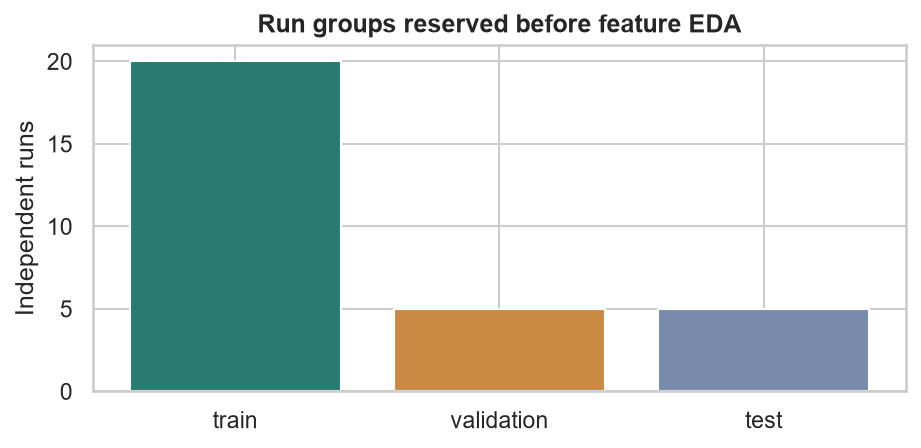

Takeaway: 20 training, 5 validation and 5 test runs are disjoint. The following charts use only 9,680 training rows; held-out feature and target distributions are not inspected.


In [3]:
rng = np.random.default_rng(SEED)
assignments = []
for scenario, group in metadata.groupby('scenario_type', sort=True):
    run_ids = rng.permutation(sorted(group.run_id.tolist()))
    for index, run_id in enumerate(run_ids):
        assignments.append({'run_id': str(run_id), 'scenario_type': scenario,
                            'split': 'train' if index < 4 else ('validation' if index == 4 else 'test')})
split_map = pd.DataFrame(assignments).sort_values('run_id').reset_index(drop=True)
assert split_map.run_id.is_unique and len(split_map) == len(metadata)
groups = {name: set(split_map.loc[split_map.split.eq(name), 'run_id']) for name in ['train','validation','test']}
assert not (groups['train'] & groups['validation'] or groups['train'] & groups['test'] or groups['validation'] & groups['test'])
split_map.to_csv(ARTIFACTS / 'run_split.csv', index=False, lineterminator='\n')
train = df[df.run_id.isin(groups['train'])].merge(metadata[['run_id','scenario_type']], on='run_id', validate='many_to_one')
assert len(train) + len(df[df.run_id.isin(groups['validation'])]) + len(df[df.run_id.isin(groups['test'])]) == len(df)
print(split_map.groupby(['scenario_type','split']).size().unstack().to_string())
print('Training shape:', train.shape, '(scenario_type is joined metadata, not a predictor)')

fig, ax = plt.subplots(figsize=(7, 3))
ax.bar(list(groups), [len(groups[name]) for name in groups], color=['#277b70','#c98b44','#798bab'])
ax.set(title='Run groups reserved before feature EDA', ylabel='Independent runs')
save_chart(fig, '02_group_split.png')
print(f'Takeaway: {len(groups["train"])} training, {len(groups["validation"])} validation and {len(groups["test"])} test runs are disjoint. The following charts use only {len(train):,} training rows; held-out feature and target distributions are not inspected.')


## Road / approach patterns (training only)

There is one abstract junction and four inbound approaches, not a real road network. Queue and wait measurements are simulator state. The rush-hour archetype chooses its dominant axis per run, so direction-specific effects can average out across runs.


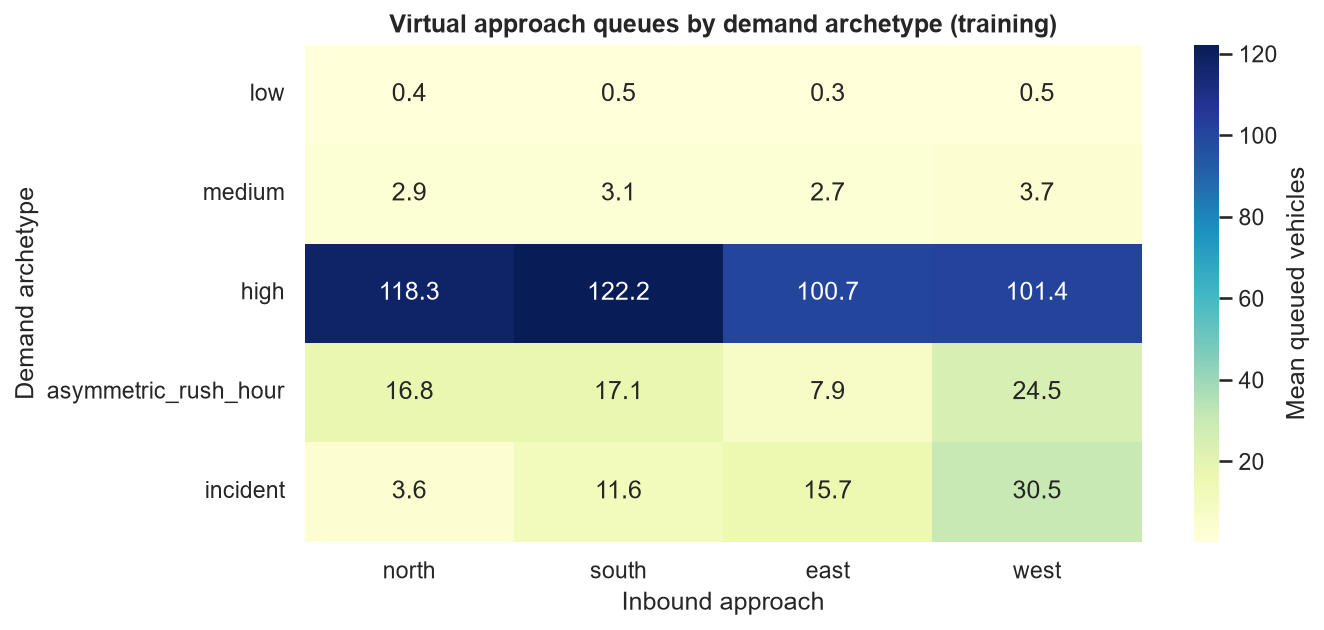

Takeaway: High-demand training rows average 110.6 queued vehicles per approach, versus 0.43 for low demand. These are synthetic single-junction differences, not evidence about real roads.


In [4]:
scenario_order = ['low','medium','high','asymmetric_rush_hour','incident']
approach_order = ['north','south','east','west']
road = train.pivot_table(index='scenario_type', columns='approach_id', values='queue_length_vehicles', aggfunc='mean').reindex(index=scenario_order, columns=approach_order)
fig, ax = plt.subplots(figsize=(9, 4.3))
sns.heatmap(road, annot=True, fmt='.1f', cmap='YlGnBu', ax=ax, cbar_kws={'label':'Mean queued vehicles'})
ax.set(title='Virtual approach queues by demand archetype (training)', xlabel='Inbound approach', ylabel='Demand archetype')
save_chart(fig, '03_approach_patterns.png')
print(f'Takeaway: High-demand training rows average {train.loc[train.scenario_type.eq("high"), "queue_length_vehicles"].mean():.1f} queued vehicles per approach, versus {train.loc[train.scenario_type.eq("low"), "queue_length_vehicles"].mean():.2f} for low demand. These are synthetic single-junction differences, not evidence about real roads.')


## Time patterns (training only)

The horizontal axis is minutes since a synthetic run began, not a live wall clock. Rush-hour-like demand is deliberately compressed into the run beginning at synthetic midnight. Curves are descriptive means over four training runs per scenario, not independent observations at every timestep or confidence intervals.


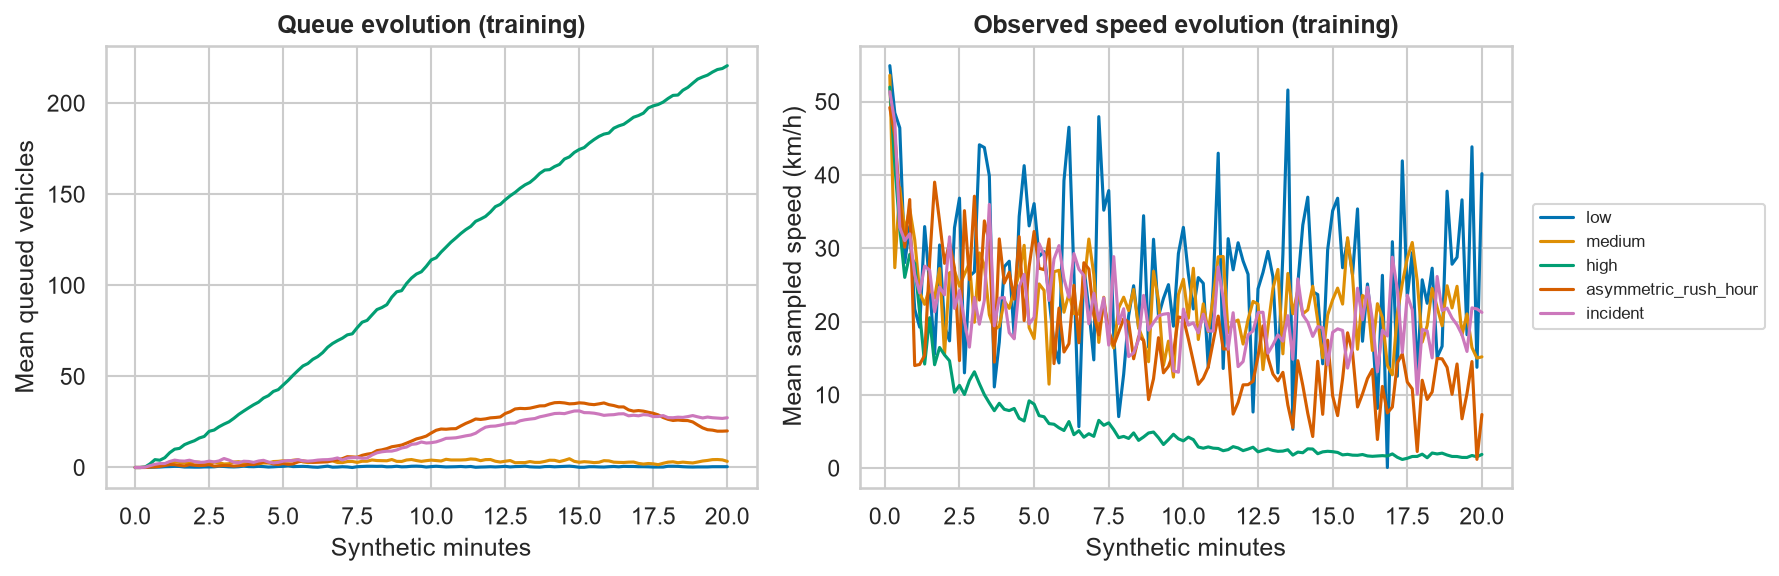

Takeaway: Empty initial states precede queue buildup; high demand leaves residual queues because arrivals can exceed fixed-time service. Incident and asymmetric demand change within-run patterns. Speed means omit unsampled rows, so these curves are conditional on coverage and are not live GPS or causal controller comparisons.


In [5]:
run_time = train.groupby(['run_id','scenario_type','timestamp_seconds'])[['queue_length_vehicles','mean_speed_kmh']].mean().reset_index()
time_pattern = run_time.groupby(['scenario_type','timestamp_seconds'])[['queue_length_vehicles','mean_speed_kmh']].mean().reset_index()
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for scenario in scenario_order:
    part = time_pattern[time_pattern.scenario_type.eq(scenario)]
    axes[0].plot(part.timestamp_seconds / 60, part.queue_length_vehicles, label=scenario)
    axes[1].plot(part.timestamp_seconds / 60, part.mean_speed_kmh, label=scenario)
axes[0].set(title='Queue evolution (training)', xlabel='Synthetic minutes', ylabel='Mean queued vehicles')
axes[1].set(title='Observed speed evolution (training)', xlabel='Synthetic minutes', ylabel='Mean sampled speed (km/h)')
axes[1].legend(fontsize=8, loc='center left', bbox_to_anchor=(1.02, .5))
fig.tight_layout()
save_chart(fig, '04_time_patterns.png')
print('Takeaway: Empty initial states precede queue buildup; high demand leaves residual queues because arrivals can exceed fixed-time service. Incident and asymmetric demand change within-run patterns. Speed means omit unsampled rows, so these curves are conditional on coverage and are not live GPS or causal controller comparisons.')


## Speed and queue distributions (training only)

Speed histograms use observed samples only; intentional nulls are retained in the data. The queue histogram includes zero queues and the long positive tail. No outliers are removed or bounds fitted.


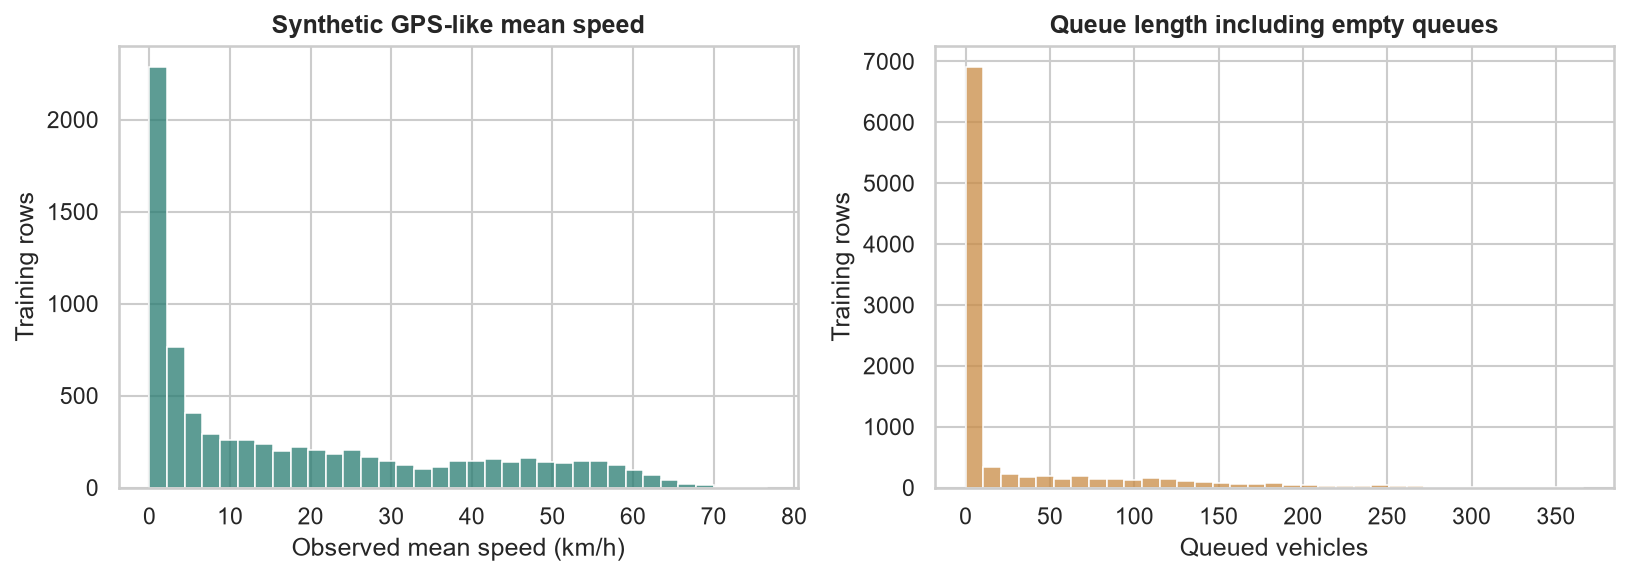

Takeaway: Training queues are zero in 34.2% of rows, while the maximum is 366 vehicles. Observed speeds mix stopped and moving traffic; missing speed is not replaced by zero, and none of these synthetic extremes are removed.


In [6]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
sns.histplot(train.mean_speed_kmh.dropna(), bins=35, ax=axes[0], color='#277b70')
sns.histplot(train.queue_length_vehicles, bins=35, ax=axes[1], color='#c98b44')
axes[0].set(title='Synthetic GPS-like mean speed', xlabel='Observed mean speed (km/h)', ylabel='Training rows')
axes[1].set(title='Queue length including empty queues', xlabel='Queued vehicles', ylabel='Training rows')
fig.tight_layout()
save_chart(fig, '05_speed_queue_distributions.png')
print(f'Takeaway: Training queues are zero in {100*train.queue_length_vehicles.eq(0).mean():.1f}% of rows, while the maximum is {train.queue_length_vehicles.max()} vehicles. Observed speeds mix stopped and moving traffic; missing speed is not replaced by zero, and none of these synthetic extremes are removed.')


## Numerical correlations (training only)

Pearson correlations use pairwise complete observations and no imputation. This excludes metadata IDs and the categorical congestion target. The future-wait column is shown as an outcome for diagnosis, never as a predictor. Correlations are descriptive; overlapping windows and repeated run observations invalidate a naive independent-row interpretation.


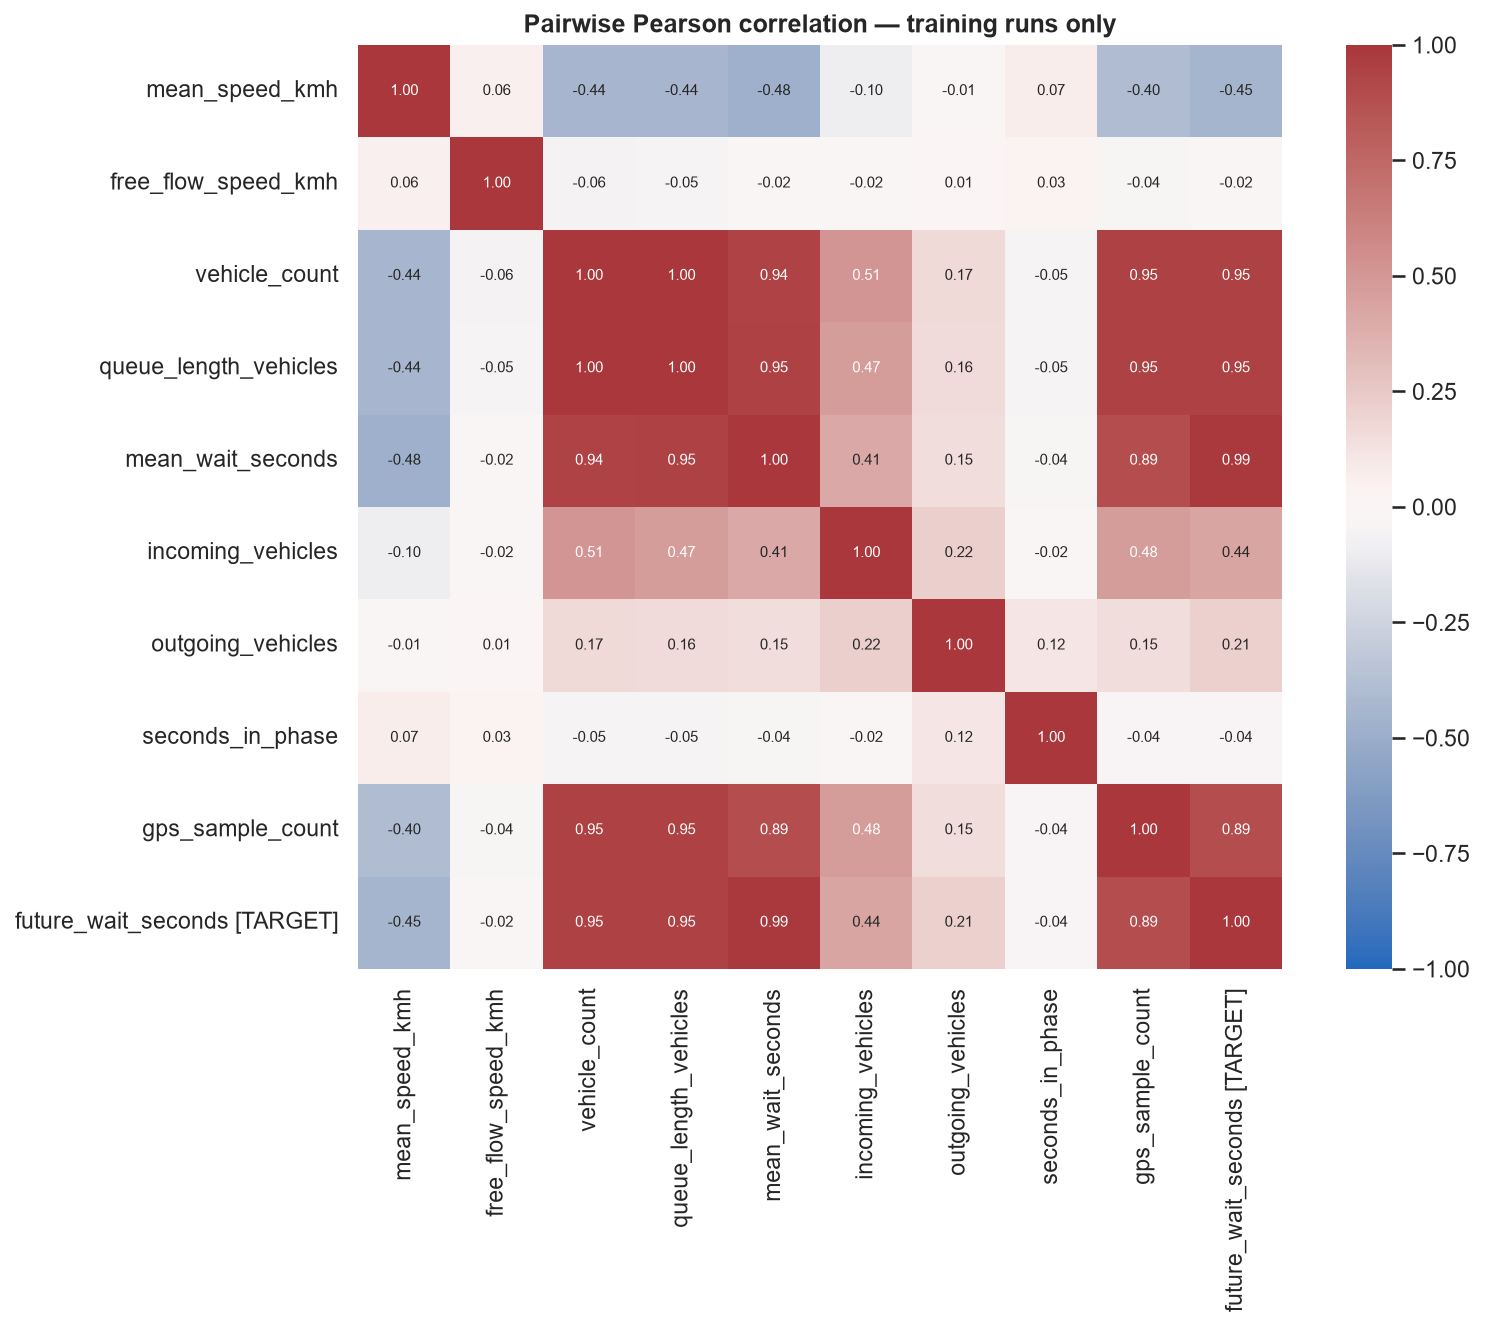

Takeaway: Current and future queue wait have correlation 0.99 in training data. Queue/count relationships reflect simulator construction and temporal persistence, not causation. Pairwise sample sizes differ when speed is missing; no feature is selected from this chart.


In [7]:
corr_columns = ['mean_speed_kmh','free_flow_speed_kmh','vehicle_count','queue_length_vehicles',
                'mean_wait_seconds','incoming_vehicles','outgoing_vehicles','seconds_in_phase',
                'gps_sample_count','future_wait_seconds']
correlation = train[corr_columns].corr()
labels = [name + (' [TARGET]' if name == 'future_wait_seconds' else '') for name in corr_columns]
fig, ax = plt.subplots(figsize=(11, 8))
sns.heatmap(correlation, vmin=-1, vmax=1, center=0, cmap='vlag', annot=True, fmt='.2f',
            xticklabels=labels, yticklabels=labels, square=True, ax=ax, annot_kws={'fontsize':7})
ax.set_title('Pairwise Pearson correlation — training runs only')
save_chart(fig, '06_correlations.png')
print(f'Takeaway: Current and future queue wait have correlation {correlation.loc["mean_wait_seconds","future_wait_seconds"]:.2f} in training data. Queue/count relationships reflect simulator construction and temporal persistence, not causation. Pairwise sample sizes differ when speed is missing; no feature is selected from this chart.')


## Future-wait target distribution (training only)

This target is the same approach's mean queue-membership wait at exactly t+60 seconds. It is not average delay over the next minute, per-vehicle trip time or independent field measurement. The extra source tail supports the exact join without zero-filling censored outcomes.


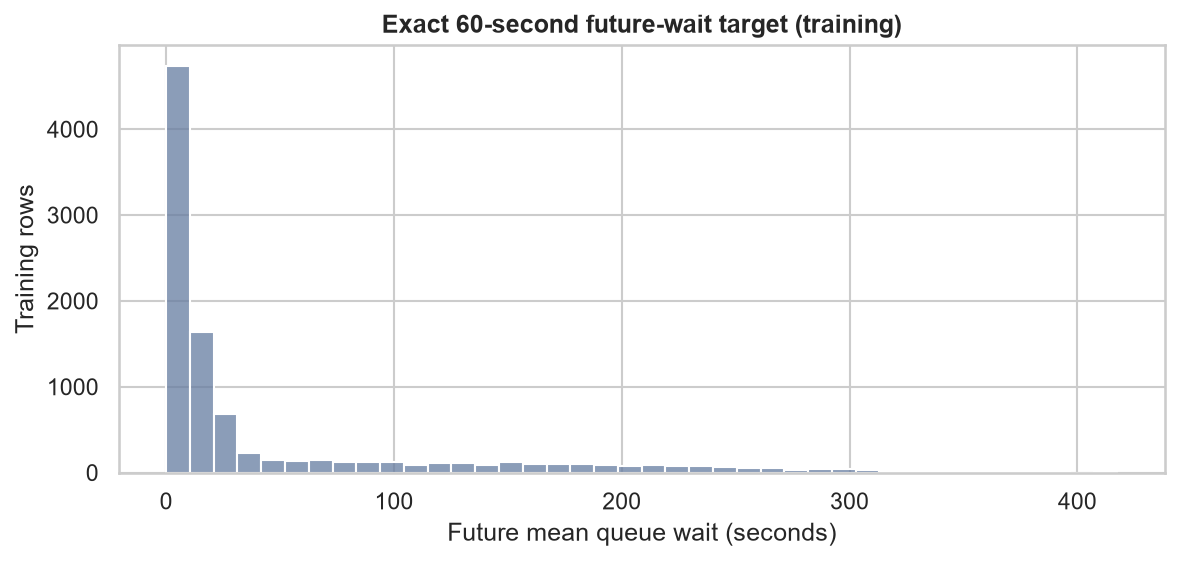

Takeaway: Future wait has median 11.0s, 95th percentile 223.7s and maximum 417.5s in training rows. Its skew and zero-wait mass call for unit-aware errors and per-run reporting; a current-wait persistence baseline should be evaluated later, not fitted here.


In [8]:
fig, ax = plt.subplots(figsize=(9, 3.7))
sns.histplot(train.future_wait_seconds, bins=40, color='#657ca0', ax=ax)
ax.set(title='Exact 60-second future-wait target (training)', xlabel='Future mean queue wait (seconds)', ylabel='Training rows')
save_chart(fig, '07_future_wait_distribution.png')
print(f'Takeaway: Future wait has median {train.future_wait_seconds.median():.1f}s, 95th percentile {train.future_wait_seconds.quantile(.95):.1f}s and maximum {train.future_wait_seconds.max():.1f}s in training rows. Its skew and zero-wait mass call for unit-aware errors and per-run reporting; a current-wait persistence baseline should be evaluated later, not fitted here.')


## Congestion target and class balance (training only)

**The classes are feature-derived.** Demand archetypes in metadata are not the congestion classes. Six runs per archetype do not imply balanced classes. The low/medium/high thresholds should not be changed to make a test-set score look better.


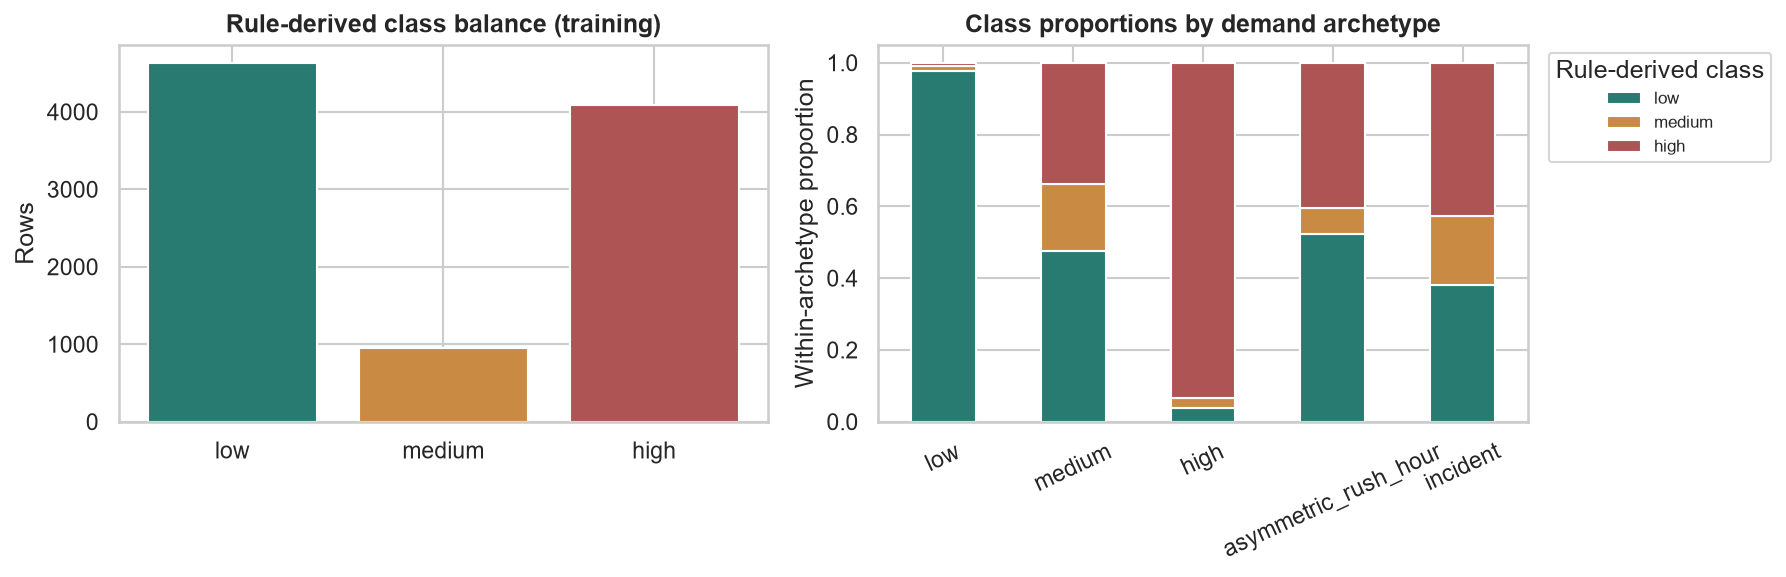

Training class counts: {'low': 4634, 'medium': 957, 'high': 4089}
Takeaway: The majority class is low (47.87% of training rows), while medium represents 9.89%. Report per-class and grouped metrics later. The label is computed from current features; high apparent accuracy can reflect rule imitation rather than useful forecasting.


In [9]:
class_order = ['low','medium','high']
class_counts = train.congestion_level.value_counts().reindex(class_order, fill_value=0)
scenario_classes = pd.crosstab(train.scenario_type, train.congestion_level, normalize='index').reindex(index=scenario_order, columns=class_order)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].bar(class_order, class_counts, color=['#277b70','#c98b44','#ae5454'])
axes[0].set(title='Rule-derived class balance (training)', ylabel='Rows')
scenario_classes.plot.bar(stacked=True, color=['#277b70','#c98b44','#ae5454'], ax=axes[1], rot=25)
axes[1].set(title='Class proportions by demand archetype', ylabel='Within-archetype proportion', xlabel='')
axes[1].legend(title='Rule-derived class', fontsize=8, loc='upper left', bbox_to_anchor=(1.02, 1))
fig.tight_layout()
save_chart(fig, '08_class_balance.png')
print('Training class counts:', class_counts.to_dict())
print(f'Takeaway: The majority class is {class_counts.idxmax()} ({100*class_counts.max()/len(train):.2f}% of training rows), while medium represents {100*class_counts["medium"]/len(train):.2f}%. Report per-class and grouped metrics later. The label is computed from current features; high apparent accuracy can reflect rule imitation rather than useful forecasting.')


## Label-definition audit, not a model evaluation

`high`: queue >=10, or current mean wait >=60, or (count >=5 and valid speed ratio <=0.35). Otherwise `medium`: queue >=5, or wait >=30, or (count >=5 and valid ratio <=0.70). Otherwise `low`. Missing ratios skip the speed branch. High takes precedence. This reproduces the documented congestion-v1 definition only; it is not a trained classifier or a predictive accuracy estimate.


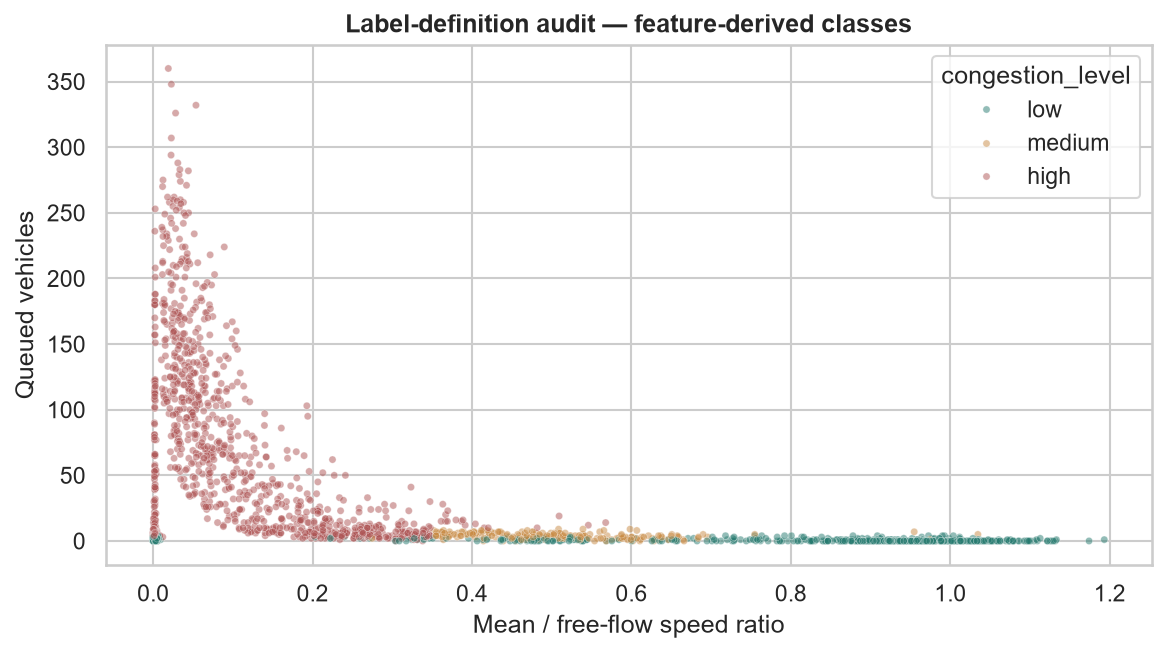

Takeaway: The documented rule agrees with 100% of training labels by construction. This is NOT model accuracy. Current queue, wait and speed help define the class, so calling a classifier on these inputs an independent congestion detector would inflate apparent performance. Group separation cannot repair that circular definition.


In [10]:
ratio = train.mean_speed_kmh / train.free_flow_speed_kmh
high_rule = train.queue_length_vehicles.ge(10) | train.mean_wait_seconds.ge(60) | (train.vehicle_count.ge(5) & ratio.le(.35))
medium_rule = train.queue_length_vehicles.ge(5) | train.mean_wait_seconds.ge(30) | (train.vehicle_count.ge(5) & ratio.le(.70))
rule_labels = np.select([high_rule, medium_rule], ['high','medium'], default='low')
rule_agreement = float(np.mean(rule_labels == train.congestion_level.to_numpy()))
assert rule_agreement == 1.0
scatter = train.assign(speed_ratio=ratio).dropna(subset=['speed_ratio']).sample(n=min(2000, int(ratio.notna().sum())), random_state=57)
fig, ax = plt.subplots(figsize=(9, 4.5))
sns.scatterplot(scatter, x='speed_ratio', y='queue_length_vehicles', hue='congestion_level',
                hue_order=class_order, palette=['#277b70','#c98b44','#ae5454'], s=12, alpha=.5, ax=ax)
ax.set(title='Label-definition audit — feature-derived classes', xlabel='Mean / free-flow speed ratio', ylabel='Queued vehicles')
save_chart(fig, '09_label_definition_audit.png')
print(f'Takeaway: The documented rule agrees with {100*rule_agreement:.0f}% of training labels by construction. This is NOT model accuracy. Current queue, wait and speed help define the class, so calling a classifier on these inputs an independent congestion detector would inflate apparent performance. Group separation cannot repair that circular definition.')


## Findings and integrity check

This notebook creates only derived charts, a split mapping, audit summaries and documentation. It does not train, transform, relabel, regenerate or rewrite any input CSV. Validation/test feature and target values stay outside the charts.


In [11]:
after_hashes = {p.name: hashlib.sha256(p.read_bytes()).hexdigest() for p in INPUTS}
assert after_hashes == input_hashes, 'Input CSV changed during EDA'
assert len(chart_paths) == 9 and all(path.is_file() for path in chart_paths)
for path in chart_paths:
    assert path.read_bytes().startswith(bytes.fromhex('89504e470d0a1a0a')), path
summary = {
    'seed':57, 'input_shape':list(df.shape), 'training_rows':len(train),
    'runs_per_split':{name:len(ids) for name,ids in groups.items()},
    'null_counts':{k:int(v) for k,v in null_counts.items()},
    'duplicate_rows':duplicate_rows, 'duplicate_keys':duplicate_keys,
    'training_class_counts':{k:int(v) for k,v in class_counts.items()},
    'rule_definition_agreement_not_accuracy':rule_agreement,
    'input_csvs_unchanged':True, 'chart_count':len(chart_paths),
    'versions':{'python':platform.python_version(),'pandas':pd.__version__,'numpy':np.__version__,
                'matplotlib':matplotlib.__version__,'seaborn':sns.__version__},
}
(ARTIFACTS / 'summary.json').write_text(json.dumps(summary,indent=2)+'\n',encoding='utf-8')
(ARTIFACTS / 'input_hashes.json').write_text(json.dumps(input_hashes,indent=2)+'\n',encoding='utf-8')
findings = f"""# EDA findings

- Input: **{len(df):,} rows x {len(df.columns)} columns**, comprising 15 current-time observation fields and two targets. Thirty synthetic runs, one virtual junction, four approaches. **Not live GPS.**
- Structural audit: {int(null_counts['mean_speed_kmh']):,} speed nulls ({100*missing_speed.mean():.2f}%), exactly matching zero sample coverage. Other columns have no nulls. Exact duplicate rows: {duplicate_rows}; duplicate observation keys: {duplicate_keys}. No imputation or deletion.
- Group split: 20 training / 5 validation / 5 test runs, stratified by demand archetype with seed 57. Charts use only **{len(train):,} training rows**. Mapping: `artifacts/eda/run_split.csv`. Held-out values are not used for feature/target EDA or tuning.
- Road/time patterns: one abstract junction, not a real road network. High-demand training rows average {road.loc['high'].mean():.2f} queued vehicles per approach versus {road.loc['low'].mean():.2f} for low demand. The rush-hour-like pulse is compressed into synthetic run time; no real commute-hour claim.
- Distributions: training queues have {100*train.queue_length_vehicles.eq(0).mean():.1f}% zeros and a maximum of {train.queue_length_vehicles.max()}. Future wait median {train.future_wait_seconds.median():.1f}s; 95th percentile {train.future_wait_seconds.quantile(.95):.1f}s. Missing speeds remain missing; observed-only speed statistics can be coverage-biased.
- Training classes: low {int(class_counts['low']):,}, medium {int(class_counts['medium']):,}, high {int(class_counts['high']):,}. Medium represents {100*class_counts['medium']/len(train):.2f}%; balanced scenario counts do not mean balanced labels.
- **Feature-derived label warning:** congestion-v1 is computed from speed/reference-speed ratio, count, queue and current wait. Direct-rule agreement is {100*rule_agreement:.0f}% **by construction, not model accuracy**. A classifier using those inputs can inflate apparent accuracy if presented as independent congestion detection. Group splits do not remove this circular definition.
- Current/future wait correlation is {correlation.loc['mean_wait_seconds','future_wait_seconds']:.2f} in training rows. Correlation reflects persistence and simulator assumptions, not causation; pairwise-complete calculations have varying sample sizes. No features are selected or preprocessing fitted here.
- Later forecasting should evaluate the exact +60s wait target, current-wait persistence baseline, MAE/RMSE in seconds, per-run variation and held-out groups. Exclude future outcomes and metadata IDs/seeds from predictors. Fit preprocessing only on training folds.
- Nine charts are saved under `artifacts/eda/` and embedded when supported. Plain-English takeaways accompany every chart. SHA-256 of all five input CSVs is unchanged. All syllabus topics remain **UNVERIFIED**; no model score or complete coverage is claimed.
"""
(ROOT / 'docs/EDA_FINDINGS.md').write_text(findings,encoding='utf-8')
print(json.dumps(summary,indent=2))
print('Input hashes unchanged: PASS. Saved docs/EDA_FINDINGS.md and nine charts.')


{
  "seed": 57,
  "input_shape": [
    14520,
    17
  ],
  "training_rows": 9680,
  "runs_per_split": {
    "train": 20,
    "validation": 5,
    "test": 5
  },
  "null_counts": {
    "run_id": 0,
    "timestamp_seconds": 0,
    "intersection_id": 0,
    "approach_id": 0,
    "mean_speed_kmh": 2761,
    "free_flow_speed_kmh": 0,
    "vehicle_count": 0,
    "queue_length_vehicles": 0,
    "mean_wait_seconds": 0,
    "incoming_vehicles": 0,
    "outgoing_vehicles": 0,
    "current_phase": 0,
    "seconds_in_phase": 0,
    "time_of_day": 0,
    "gps_sample_count": 0,
    "congestion_level": 0,
    "future_wait_seconds": 0
  },
  "duplicate_rows": 0,
  "duplicate_keys": 0,
  "training_class_counts": {
    "low": 4634,
    "medium": 957,
    "high": 4089
  },
  "rule_definition_agreement_not_accuracy": 1.0,
  "input_csvs_unchanged": true,
  "chart_count": 9,
  "versions": {
    "python": "3.12.14",
    "pandas": "3.1.0",
    "numpy": "2.5.4",
    "matplotlib": "3.11.2",
    "seaborn": "0.1